<a href="https://colab.research.google.com/github/wahyurqwertyuiop-crypto/pm-turi4-clustering/blob/main/PM_Praktikum_Pertemuan9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mata Kuliah: Pembelajaran Mesin Pertemuan 9

Nama: Wahyu Ramdhani
NIM: 2488010037

In [24]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

def kelompok(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia': rng.normal(*usia, n),
        'pendapatan': rng.normal(*pendapatan, n),
        'skor_belanja': rng.normal(*skor, n)
    })

df = pd.concat([
    kelompok(100, (25, 4), (300, 60),  (80, 8)),   # muda, belanja tinggi
    kelompok(100, (45, 5), (900, 100), (55, 10)),  # paruh baya, pendapatan tinggi
    kelompok(100, (62, 5), (450, 70),  (20, 7)),   # senior, hemat
], ignore_index=True)

df['usia'] = df['usia'].clip(18, 70).round(0)
df['pendapatan'] = df['pendapatan'].clip(50, None).round(0)
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round(0)

print(df.shape)
df.head()

(300, 3)


,usia,pendapatan,skor_belanja
0,26.0,277.0,83.0
1,21.0,378.0,91.0
2,28.0,279.0,81.0
3,29.0,344.0,85.0
4,18.0,244.0,64.0


In [25]:
df.describe().round(1)

,usia,pendapatan,skor_belanja
count,300.0,300.0,300.0
mean,43.9,549.2,50.8
std,15.6,264.8,26.4
min,18.0,172.0,1.0
25%,27.0,325.0,22.0
50%,46.0,455.0,54.0
75%,58.0,832.8,75.0
max,70.0,1160.0,100.0


In [26]:
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)

print("Rata-rata setelah scaling :", X_scaled.mean(axis=0).round(2))
print("Std setelah scaling       :", X_scaled.std(axis=0).round(2))

Rata-rata setelah scaling : [ 0.  0. -0.]
Std setelah scaling       : [1. 1. 1.]


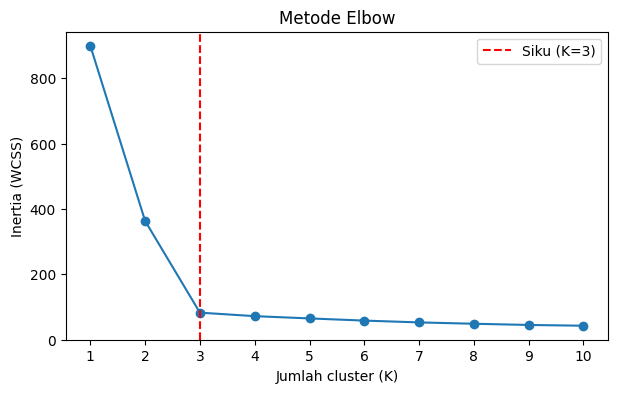

K= 1  inertia=   900.0
K= 2  inertia=   363.6
K= 3  inertia=    82.7
K= 4  inertia=    72.0
K= 5  inertia=    65.0
K= 6  inertia=    58.4
K= 7  inertia=    52.8
K= 8  inertia=    48.7
K= 9  inertia=    45.0
K=10  inertia=    42.7


In [27]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(3, color='red', linestyle='--', label='Siku (K=3)')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Metode Elbow')
plt.xticks(range(1, 11))
plt.legend()
plt.show()

for k, val in zip(range(1, 11), inertias):
    print(f"K={k:2d}  inertia={val:8.1f}")

In [28]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)   # tanpa y (tak berlabel)

print(df['cluster'].value_counts().sort_index())
print("\nInertia:", round(kmeans.inertia_, 1))
print("Centroid (ruang ter-scaling):\n", kmeans.cluster_centers_.round(2))

cluster
0    100
1    100
2    100
Name: count, dtype: int64

Inertia: 82.7
Centroid (ruang ter-scaling):
 [[ 1.12 -0.37 -1.21]
 [-1.22 -0.95  1.09]
 [ 0.11  1.31  0.12]]


In [29]:
sil_k3 = silhouette_score(X_scaled, df['cluster'])
print("Silhouette score (K=3):", round(sil_k3, 3))

Silhouette score (K=3): 0.728


In [30]:
profil = df.groupby('cluster')[['usia', 'pendapatan', 'skor_belanja']].mean().round(1)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
print(profil)

         usia  pendapatan  skor_belanja  jumlah
cluster                                        
0        61.3       452.6          18.8     100
1        24.8       299.4          79.5     100
2        45.5       895.5          54.0     100


In [31]:
nama = {}
nama[profil['skor_belanja'].idxmax()] = 'Muda belanja tinggi'
nama[profil['pendapatan'].idxmax()]   = 'Mapan berpenghasilan tinggi'
nama[profil['skor_belanja'].idxmin()] = 'Senior hemat'

df['segmen'] = df['cluster'].map(nama)
profil['segmen'] = profil.index.map(nama)
profil

,usia,pendapatan,skor_belanja,jumlah,segmen
cluster,,,,,
0,61.3,452.6,18.8,100,Senior hemat
1,24.8,299.4,79.5,100,Muda belanja tinggi
2,45.5,895.5,54.0,100,Mapan berpenghasilan tinggi


In [32]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, label5)

print(f"Silhouette K=3 : {sil_k3:.3f}")
print(f"Silhouette K=5 : {sil_k5:.3f}")
print("Ukuran cluster K=5:", np.bincount(label5))

Silhouette K=3 : 0.728
Silhouette K=5 : 0.587
Ukuran cluster K=5: [100  40 100  24  36]


Latihan Mandiri no.6:

Silhouette K=5 lebih rendah daripada K=3. Data sebenarnya hanya memiliki 3 kelompok alami, sehingga K=5 memecah kelompok yang utuh menjadi potongan-potongan kecil yang saling berdekatan (jarak antar-cluster mengecil). Inertia memang turun, tetapi kualitas pemisahan memburuk. Ini menunjukkan bahwa inertia saja tidak cukup untuk memilih K; silhouette membantu memastikannya.

In [33]:
X_raw = df[['usia', 'pendapatan', 'skor_belanja']].values

km_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
label_raw = km_raw.fit_predict(X_raw)

sil_raw        = silhouette_score(X_raw, label_raw)        # dihitung di ruang data mentah
sil_raw_scaled = silhouette_score(X_scaled, label_raw)     # dihitung di ruang ter-scaling (adil)

print(f"Silhouette DENGAN scaling                      : {sil_k3:.3f}")
print(f"Silhouette TANPA scaling (ruang mentah)        : {sil_raw:.3f}")
print(f"Silhouette TANPA scaling (diukur di ruang scaled): {sil_raw_scaled:.3f}")

# Berapa banyak titik yang berpindah cluster dibanding hasil dengan scaling?
from sklearn.metrics import adjusted_rand_score
print("Kesamaan pengelompokan dengan vs tanpa scaling (ARI):",
      round(adjusted_rand_score(df['cluster'], label_raw), 3), "(1.0 = identik)")
print("Ukuran cluster tanpa scaling:", np.bincount(label_raw))

Silhouette DENGAN scaling                      : 0.728
Silhouette TANPA scaling (ruang mentah)        : 0.626
Silhouette TANPA scaling (diukur di ruang scaled): 0.552
Kesamaan pengelompokan dengan vs tanpa scaling (ARI): 0.785 (1.0 = identik)
Ukuran cluster tanpa scaling: [ 99  98 103]


Latihan Mandiri 7:
- Tanpa scaling, jarak hampir sepenuhnya ditentukan oleh `pendapatan` karena angkanya paling besar, sedangkan `usia` dan `skor_belanja` nyaris tidak berpengaruh.
- Akibatnya sebagian pelanggan masuk ke cluster yang salah (ARI < 1, pengelompokan berbeda dari hasil dengan scaling). Jika silhouette dihitung di ruang yang sama (scaled), nilai tanpa scaling lebih rendah.
- Hati-hati: silhouette tanpa scaling yang dihitung di ruang mentah tidak bisa langsung dibandingkan dengan silhouette ruang scaled, karena skala jaraknya berbeda. Itulah mengapa dua angka dicetak.
- Kesimpulan: scaling wajib untuk algoritma berbasis jarak seperti K-Means.

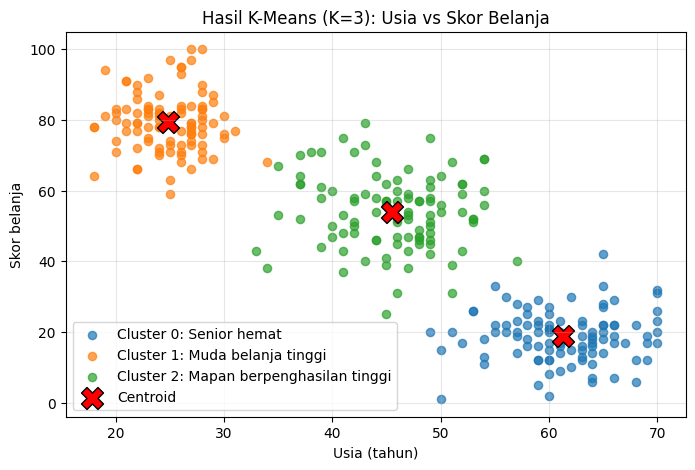

In [34]:
warna = ['tab:blue', 'tab:orange', 'tab:green']
plt.figure(figsize=(8, 5))
for c in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == c]
    plt.scatter(sub['usia'], sub['skor_belanja'], s=35, alpha=0.7,
                color=warna[c], label=f"Cluster {c}: {nama[c]}")

# gambar centroid (dikembalikan ke skala asli)
pusat = StandardScaler().fit(df[['usia', 'pendapatan', 'skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
plt.scatter(pusat[:, 0], pusat[:, 2], c='red', marker='X', s=250, edgecolor='black', label='Centroid')

plt.xlabel('Usia (tahun)')
plt.ylabel('Skor belanja')
plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Refleksi
Refleksi no.9:

Bagaimana K-Means menemukan kelompok tanpa label?
K-Means tidak membutuhkan jawaban benar. Ia hanya memakai kemiripan berdasarkan jarak. Mulai dari K centroid acak, setiap titik dimasukkan ke centroid terdekat (assignment), lalu centroid dihitung ulang sebagai rata-rata anggotanya (update). Siklus ini diulang sampai centroid tidak berpindah lagi (konvergen). Hasil akhirnya adalah kelompok yang anggotanya saling dekat dan berjauhan dari kelompok lain, tanpa pernah diberi label.


Refleksi no.10:

Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
Karena data memang dibangun dari 3 kelompok alami. Menambah cluster dari 1 ke 2 lalu 3 memisahkan kelompok-kelompok nyata sehingga inertia turun tajam. Setelah K=3, setiap cluster sudah rapat, sehingga cluster tambahan hanya membelah kelompok yang sebenarnya satu dan perbaikan inertia menjadi kecil (kurva landai).


Refleksi no.11:

Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
K-Means memakai jarak Euclidean, sehingga fitur dengan skala besar mendominasi perhitungan jarak. Tanpa scaling, `pendapatan` (ratusan) menutupi `usia` dan `skor_belanja` (puluhan). Dampaknya: batas cluster hanya mengikuti satu fitur, ada titik yang salah kelompok, dan kualitas pengelompokan menurun (terlihat pada Latihan 7).

